<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">
<h1 style="color:#0F2A4A">نوت‌بوک ۱ — الگوریتم نزدیک‌ترین همسایه‌ها (KNN)</h1>
<h2 style="color:#0E7490">k-Nearest Neighbors</h2>
<p>KNN یک متد <b>غیرپارامتری مبتنی بر فاصله</b> است: نمونه جدید به کلاسی می‌رود که اکثریت k همسایه نزدیکش در آن هستند (رأی‌گیری اکثریت).</p>
<p>در این نوت‌بوک:</p>
<ul><li>مثال اسلاید درس: پیش‌بینی پرداخت اقساط مشتری جدید با فاصله منهتن</li><li>اجرا روی دیتاست Iris: مرز تصمیم و انتخاب k</li><li>اثر نرمال‌سازی روی فاصله‌ها</li></ul>
<p style="color:#45607A; font-size:13px">همراه ارائه درس «داده‌کاوی و یادگیری ماشین» — برای اجرا در Google Colab: هر سلول را با <b>Shift+Enter</b> اجرا کنید و پارامترها را آزادانه تغییر دهید.</p>
<hr style="border:0;border-top:1px dashed #B7DFEA;margin:10px 0">
<p style="background:#EBF7FA;border:1px solid #B7DFEA;border-radius:8px;padding:10px 12px">
🛠 <b>راهنمای استفاده:</b> همهٔ کدها در <b>Google Colab</b> اجرا می‌شوند — بدون نصبِ پایتون یا کتابخانه؛ فقط مرورگر و اینترنت (اجرای هر سلول: <b>Shift+Enter</b> یا منوی Runtime ▸ Run all).<br>
🐍 <b>یادگیری پایتون، از صفر:</b> <a href="https://www.w3schools.com/python/default.asp">W3Schools — Python Tutorial</a> — آموزش تعاملی و رایگان؛ مثال‌ها را همان‌جا اجرا و ویرایش کنید.<br>
📝 <b>هر سلول:</b> توضیح فارسی در بالای سلول و کامنت‌های فارسی داخل کد آمده است؛ خروجی‌ها هم از قبل ذخیره شده‌اند.
</p>
</div>

In [1]:
# تنظیمات اولیه: واردکردن کتابخانه‌ها + پالت رنگی و ظاهر یکسان نمودارها
import numpy as np, pandas as pd, matplotlib.pyplot as plt
TEAL, NAVY, AMBER = "#0E7490", "#0F2A4A", "#B45309"
plt.rcParams.update({"figure.facecolor":"white","axes.grid":True,"grid.color":"#D8E2EC",
    "axes.edgecolor":"#94A3B8","axes.labelcolor":"#0F2A4A","text.color":"#0F2A4A",
    "axes.titlecolor":"#0F2A4A","axes.titleweight":"bold","legend.frameon":False,
    "xtick.color":"#334155","ytick.color":"#334155"})
print("libraries ready")

libraries ready


<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">
<h2 style="color:#0F2A4A">۱) مثال اسلاید درس: مشتری جدید اقساط را به‌موقع پرداخت می‌کند؟</h2>
<p>همان مثال کلاس: ۱۰ مشتری با سه ویژگی (سن، درآمد ماهانه، سابقه پرداخت به‌موقع). فاصله <b>منهتن</b> مشتری جدید را از همه محاسبه می‌کنیم و با k=4 رأی‌گیری می‌کنیم.</p>
</div>

In [2]:
# دادهٔ وام (مثال اسلاید درس): ۱۰ مشتری + مشتری جدید؛ محاسبهٔ فاصلهٔ منهتن برای هر مشتری
import pandas as pd, numpy as np

loan = pd.DataFrame({
    "Age":       [22, 25, 27, 31, 35, 38, 42, 45, 48, 55],
    "Income":    [12, 14, 18, 30, 35, 40, 50, 38, 45, 60],
    "OnTimeYrs": [ 1,  1,  2,  6,  8,  9, 12, 11, 15, 20],
    "PaidOnTime": ["No","No","No","Yes","Yes","Yes","Yes","Yes","Yes","Yes"],
})
new_cust = np.array([33, 32, 5])          # Age, Income, OnTimeYrs

# Manhattan distance: sum of absolute differences
loan["Manhattan"] = (loan[["Age","Income","OnTimeYrs"]] - new_cust).abs().sum(axis=1)
loan.index += 1
loan

,Age,Income,OnTimeYrs,PaidOnTime,Manhattan
1,22,12,1,No,35
2,25,14,1,No,30
3,27,18,2,No,23
4,31,30,6,Yes,5
5,35,35,8,Yes,8
6,38,40,9,Yes,17
7,42,50,12,Yes,34
8,45,38,11,Yes,24
9,48,45,15,Yes,38
10,55,60,20,Yes,65


In [3]:
# رأی‌گیری اکثریت بین k=۴ همسایهٔ نزدیک — پیش‌بینی برای مشتری جدید
k = 4
nearest = loan.Manhattan.nsmallest(k).index
vote = loan.loc[nearest, "PaidOnTime"].value_counts()
print("nearest customers:", list(nearest))
print("vote:\n", vote)
print("prediction ->", vote.idxmax())

nearest customers: [4, 5, 6, 3]
vote:
 PaidOnTime
Yes    3
No     1
Name: count, dtype: int64
prediction -> Yes


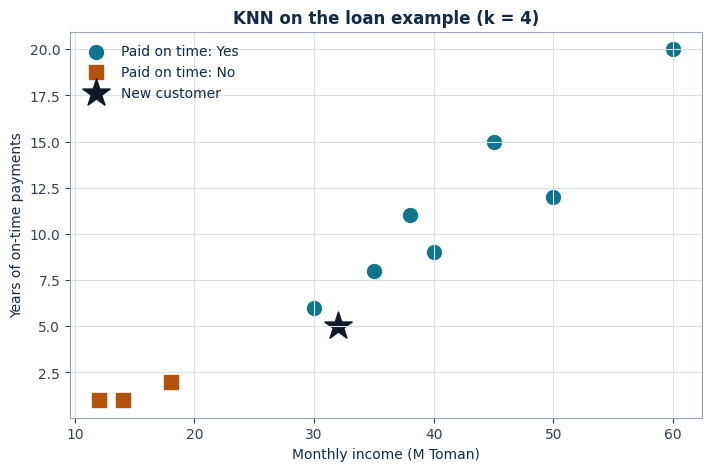

In [4]:
# مصورسازی مثال وام: ستارهٔ سیاه = مشتری جدید (همان شکل اسلاید ارائه)
fig, ax = plt.subplots(figsize=(7,4.6), layout="constrained")
for lab, col, mk in [("Yes", TEAL, "o"), ("No", AMBER, "s")]:
    s = loan[loan.PaidOnTime == lab]
    ax.scatter(s.Income, s.OnTimeYrs, c=col, marker=mk, s=100, label=f"Paid on time: {lab}")
ax.scatter(32, 5, marker="*", s=430, c="#111827", label="New customer")
ax.set_xlabel("Monthly income (M Toman)"); ax.set_ylabel("Years of on-time payments")
ax.set_title(f"KNN on the loan example (k = {k})"); ax.legend()
plt.show()

<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">
<h2 style="color:#0F2A4A">۲) KNN روی دیتاست Iris</h2>
<p>۱۵۰ گل زنبق در ۳ کلاس با ۴ ویژگی. طبق اسلایدهای درس داده را <b>۸۵٪ آموزش / ۱۵٪ آزمون</b> تقسیم می‌کنیم.</p>
</div>

In [5]:
# بارگذاری Iris، تقسیم ۸۵٪/۱۵٪ با stratify، و KNN با k=۵
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

X, y = load_iris(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.15,
                                          random_state=42, stratify=y)
print("train:", X_tr.shape[0], "| test:", X_te.shape[0])

knn = KNeighborsClassifier(n_neighbors=5)      # k = 5
knn.fit(X_tr, y_tr)
print("Test accuracy:", knn.score(X_te, y_te))

train: 127 | test: 23
Test accuracy: 1.0


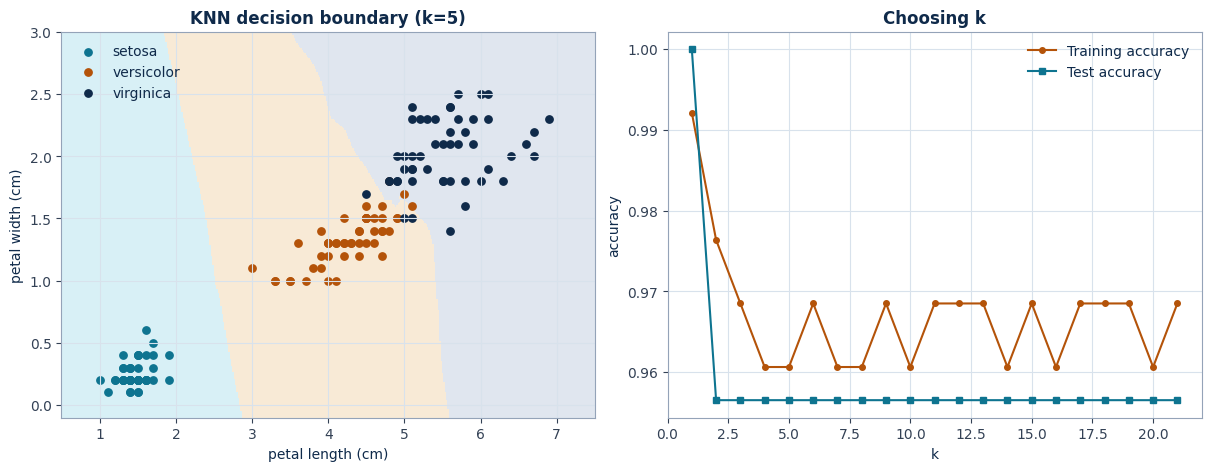

In [6]:
# مرز تصمیم KNN (k=۵) روی دو ویژگی گلبرگ + نمودار دقت بر حسب k
# decision boundary on the two petal features
from matplotlib.colors import ListedColormap
Xp = X[:, 2:4]
Xp_tr, Xp_te, yp_tr, yp_te = train_test_split(Xp, y, test_size=.15,
                                              random_state=42, stratify=y)
knn5 = KNeighborsClassifier(n_neighbors=5).fit(Xp_tr, yp_tr)

fig, axes = plt.subplots(1, 2, figsize=(12,4.6), layout="constrained")
cmap = ListedColormap(["#B9E5F0","#F3D9B5","#C7D2E3"])
xx, yy = np.meshgrid(np.linspace(0.5, 7.5, 400), np.linspace(-0.1, 3, 400))
Z = knn5.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
axes[0].pcolormesh(xx, yy, Z, cmap=cmap, alpha=.55, shading="auto")
for c, col in [(0,TEAL),(1,AMBER),(2,NAVY)]:
    s = y == c
    axes[0].scatter(Xp[s,0], Xp[s,1], c=col, s=28, label=load_iris().target_names[c])
axes[0].set_xlabel("petal length (cm)"); axes[0].set_ylabel("petal width (cm)")
axes[0].set_title("KNN decision boundary (k=5)"); axes[0].legend()

ks, tr_acc, te_acc = range(1,22), [], []
for k in ks:
    m = KNeighborsClassifier(n_neighbors=k).fit(Xp_tr, yp_tr)
    tr_acc.append(m.score(Xp_tr, yp_tr)); te_acc.append(m.score(Xp_te, yp_te))
axes[1].plot(ks, tr_acc, "-o", color=AMBER, ms=4, label="Training accuracy")
axes[1].plot(ks, te_acc, "-s", color=TEAL, ms=4, label="Test accuracy")
axes[1].set_xlabel("k"); axes[1].set_ylabel("accuracy")
axes[1].set_title("Choosing k"); axes[1].legend()
plt.show()

<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">
<h2 style="color:#0F2A4A">۳) نکته مهم: نرمال‌سازی</h2>
<p>چون مبنای KNN <b>فاصله</b> است، ویژگی با مقیاس بزرگ‌تر (اینجا درآمد) فاصله را دیکته می‌کند. اگر ستون‌ها را نرمال کنیم، ترتیب همسایه‌ها می‌تواند عوض شود — همان نکته اسلاید درس.</p>
</div>

In [7]:
# مقایسهٔ فاصلهٔ خام و نرمال‌شده (Min-Max) در مثال وام — رتبه‌ها را ببینید
# normalized (min-max) Manhattan on the loan example
L = loan[["Age","Income","OnTimeYrs"]]
L_norm = (L - L.min()) / (L.max() - L.min())
new_norm = (new_cust - L.min()) / (L.max() - L.min())

d_raw  = L.apply(lambda r: (r - new_cust).abs().sum(), axis=1)
d_norm = L_norm.apply(lambda r: (r - new_norm).abs().sum(), axis=1)
cmp = pd.DataFrame({"raw dist": d_raw, "normalized dist": d_norm})
cmp["rank_raw"] = cmp["raw dist"].rank().astype(int)
cmp["rank_norm"] = cmp["normalized dist"].rank().astype(int)
print(cmp.sort_values("raw dist").head(6))
print("\n4 nearest (normalized):", list(cmp["normalized dist"].nsmallest(4).index))

   raw dist  normalized dist  rank_raw  rank_norm
4         5         0.154904         1          1
5         8         0.281001         2          2
6        17         0.528708         3          3
3        23         0.631380         4          4
8        24         0.804426         5          5
2        30         0.827951         6          6

4 nearest (normalized): [4, 5, 6, 3]


<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">
<h2 style="color:#0F2A4A">۴) انتخاب k — نمودار دقت بر حسب k (همان اسلاید «چالش انتخاب k»)</h2>
<p>تقسیم استاندارد درس: <b>۸۰٪ آموزش / ۲۰٪ آزمون</b> با <code>random_state=42</code> و <code>stratify=y</code>؛ و چون KNN فاصله‌محور است، مدل را داخل <b>Pipeline</b> با <code>StandardScaler</code> نرمال می‌کنیم (درس اسلاید مقیاس‌دهی — جلوگیری از نشت داده).</p>
<p>با <b>k=۱</b> مدل به نویز حساس می‌شود (بیش‌برازش) و با k خیلی بزرگ، مرز بیش‌ازحد ساده می‌شود (کم‌برازش). سلول زیر برای هر k فردِ ۱ تا ۲۵، دقت آموزش و آزمون را می‌سازد — <b>همان نمودار ارائه، با همین اعداد.</b></p>
</div>

k= 1 | train acc = 1.0000 | test acc = 0.9667
k= 3 | train acc = 0.9583 | test acc = 0.9333
k= 5 | train acc = 0.9750 | test acc = 0.9333
k= 7 | train acc = 0.9750 | test acc = 0.9667
k= 9 | train acc = 0.9583 | test acc = 0.9667
k=11 | train acc = 0.9583 | test acc = 0.9667
k=13 | train acc = 0.9583 | test acc = 0.9667
k=15 | train acc = 0.9667 | test acc = 0.9667
k=17 | train acc = 0.9583 | test acc = 0.9667
k=19 | train acc = 0.9417 | test acc = 0.9667
k=21 | train acc = 0.9500 | test acc = 0.9667
k=23 | train acc = 0.9583 | test acc = 0.9333
k=25 | train acc = 0.9583 | test acc = 0.9000

Highest test accuracy = 0.9667, reached at k = [1, 7, 9, 11, 13, 15, 17, 19, 21]
Demo choice (slide 7): k = 5 (odd; final pick by cross-validation)


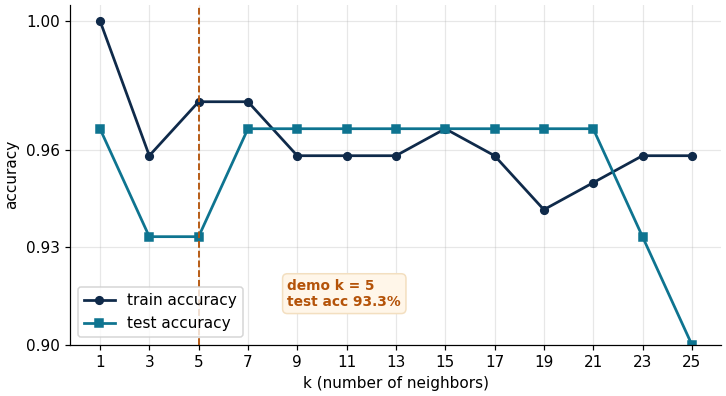

In [ ]:
# بخش ۴ — k-sweep: برای هر k فرد، دقت آموزش/آزمون (همان دستورِ اسلاید «چالش انتخاب k»)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2,   # تقسیم استاندارد ۸۰/۲۰
                                          random_state=42, stratify=y)
ks, tr, te = [], [], []
for k in range(1, 26, 2):                       # فقط k های فرد
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)).fit(X_tr, y_tr)
    ks.append(k); tr.append(m.score(X_tr, y_tr)); te.append(m.score(X_te, y_te))
    print(f"k={k:2d} | train acc = {tr[-1]:.4f} | test acc = {te[-1]:.4f}")

top = max(te)                                   # بالاترین دقت آزمون
plateau = [k for k, a in zip(ks, te) if a == top]   # همهٔ kهایی که به آن رسیدند
print(f"\nHighest test accuracy = {top:.4f}, reached at k = {plateau}")
print("Demo choice (slide 7): k = 5 (odd; final pick by cross-validation)")

# همان نمودار ارائه — دقت آموزش و آزمون بر حسب k
fig, ax = plt.subplots(figsize=(6.6, 3.6), layout="constrained")
ax.plot(ks, tr, "-o", color="#0F2A4A", ms=5, lw=1.8, label="train accuracy")
ax.plot(ks, te, "-s", color="#0E7490", ms=5, lw=1.8, label="test accuracy")
ax.axvline(5, ls="--", color="#B45309", lw=1.2)       # انتخاب دمو (k=۵)
ax.annotate("demo k = 5\ntest acc 93.3%", xy=(5, 0.9333), xytext=(8.6, 0.912),
            fontsize=9, color="#B45309", weight="bold",
            bbox=dict(boxstyle="round,pad=0.35", fc="#FFF6E9", ec="#F3DFC0"))
ax.set_xlabel("k (number of neighbors)"); ax.set_ylabel("accuracy")
ax.set_xticks(ks); ax.set_ylim(0.90, 1.005)
ax.grid(alpha=.3); ax.set_axisbelow(True)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
ax.legend(loc="lower left")
plt.show()

<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">
<p><b>نتیجه:</b> با k=۱ دقت آموزش ۱۰۰٪ است ولی آزمون ۹۶٫۷٪ — شکافِ آموزش/آزمون، نشانهٔ حساسیت به نویز. بالاترین دقت آزمون (۹۶٫۷٪) در بازهٔ k≈۷ تا ۲۱ تکرار می‌شود و در k=۲۵ به ۹۰٪ می‌افتد. سه قاعدهٔ درس: k <b>فرد</b>، شروع از حدود <b>√n</b> (اینجا n=۱۲۰، پس ≈ ۱۱)، و انتخاب نهایی با <b>اعتبارسنجی متقاطع</b>.</p>
</div>

<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">
<h2 style="color:#0F2A4A">جمع‌بندی</h2>
<ul><li>KNN فقط با «فاصله گرفتن» پیش‌بینی می‌کند — هیچ مرحله آموزشی ندارد</li><li>انتخاب k تعادل است: k کوچک = حساس به نویز، k بزرگ = بیش‌حد ساده</li><li>همیشه داده را نرمال کنید وقتی مقیاس ویژگی‌ها متفاوت است</li></ul>
<p style="color:#45607A">قدم بعدی: پارامترها (مثل k یا max_depth) را تغییر دهید و اثرشان را روی خروجی ببینید.</p>
</div>